# Task 4 Semi-supervised learning for unlabeled data

## Imports

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import missingno as msno
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict
from xgboost import XGBRegressor
from catboost import CatBoostRegressor, Pool
from sklearn.manifold import Isomap
from sklearn.decomposition import PCA

## Auxiliary functions

In [37]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    # Only one target variable: SurvivalTime
    label = 'SurvivalTime'
    MAX = 500

    # Select indices for plotting
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    # Plot True vs Predicted for SurvivalTime
    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    # Create a DataFrame with the 'id' column and the predictions
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    # Save the DataFrame to a CSV file
    df.to_csv(path, index=False)
    
def model_metrics(y_true, y_pred):
    error = y_true - y_pred
    metrics = {
        'Metric': ['Max Error', 'Min Error', 'Mean Error', 'Std of Error'],
        'Value': [
            np.max(np.abs(error)),
            np.min(np.abs(error)),
            np.mean(np.abs(error)),
            np.std(error)
        ]
    }
    return pd.DataFrame(metrics)


def evaluate_model(X, y, c, model, show_cmse=True, show_metrics=False, show_plot=False):

    X = np.array(X)
    y = np.array(y)
    c = np.array(c)
    
    # Train-test split
    X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=30)
    
    # Cross validation
    y_pred_cv = cross_val_predict(model, X_train, y_train, cv=10)
    cMSE_cv = cMSE(y_train, y_pred_cv, c_train)
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    cMSE_test = cMSE(y_test, y_pred, c_test)
    
    if show_cmse:
        print(f"CV cMSE: {cMSE_cv}")
        print(f"Test cMSE: {cMSE_test}")
    
    if show_metrics:
        metrics = model_metrics(y_test, y_pred)
        print(metrics.T.to_string(index=False, header=False))
    
    if show_plot:
        plot_y_yhat(y_test, y_pred, plot_title="y_yhat_plot")
    
    return model, cMSE_cv

## Data preprocessing

In [18]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
print(f"Remaining points: {df.shape[0]}")

Remaining points: 400


In [15]:
X = df
y = df['SurvivalTime']
c = df['Censored']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

# X = np.array(X)
# y = np.array(y)
# c = np.array(c)

Feature matrix X shape: (400, 9)
Target vector y shape: (400,)
Censored vector c shape: (400,)


# Task 4.1: Imputation with labeled and unlabeled data

In [20]:
labeled_df = df.dropna(subset=['SurvivalTime'])
unlabeled_df = df[df['SurvivalTime'].isna()]

X_labeled = labeled_df.drop(columns=['SurvivalTime', 'Censored'])
y_labeled = labeled_df['SurvivalTime']
c_labeled = labeled_df['Censored']

X_unlabeled = unlabeled_df.drop(columns=['SurvivalTime', 'Censored'])
c_unlabeled = unlabeled_df['Censored']

X_combined = pd.concat([X_labeled, X_unlabeled])

Pipeline for Linear Regression with Standard Scaler

In [10]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())

Fit with the best imputation methods from Task 3.1

Best imputer from task 3.1 was KNN imputer with K=19

In [25]:
imputer = KNNImputer(n_neighbors=19)
X_combined_imp = pd.DataFrame(imputer.fit_transform(X_combined), columns=X_combined.columns)

CV cMSE: 2.606016778008581
Test cMSE: 2.418972175074191


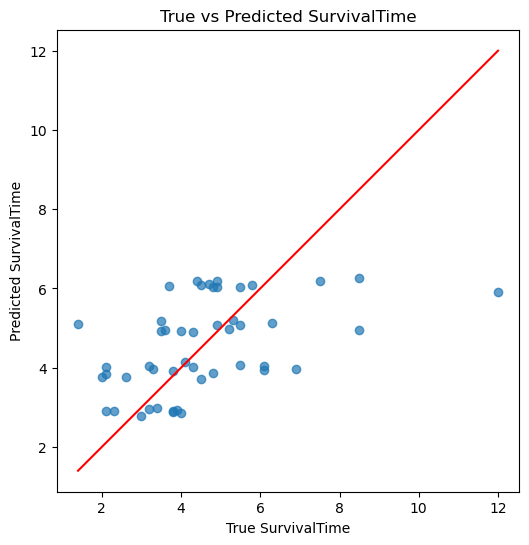

In [38]:
X_labeled_imp = X_combined_imp.iloc[:len(labeled_df)]
lr_imp_model, lr_imp_csme = evaluate_model(X_labeled_imp, y_labeled, c_labeled, model=linear_reg, show_plot=True)